# CaSR v3.2 → Saskatoon (OOD test set)

Builds the **out-of-distribution** evaluation set: Saskatoon, 2015–2018, pulled from
CaSR v3.2 the *exact same way* as the Vancouver training set, so the only thing that
differs between them is **location**. That is what makes the Vancouver→Saskatoon
comparison a clean test of geographic generalization.

**Identical to the Vancouver loader except:**
- City centre → Saskatoon (52.13 N, -106.67 W), a cooler prairie climate.
- Output filename → `casr_saskatoon_2015_2018.npz`.

Everything else — variable (`tas`, 1.5 m mean temperature), box size (`HALF_DEG`),
coarsening factor, patch size/stride, date window — is kept the same ON PURPOSE. Do not
change these here; if you change them, change them in the Vancouver loader too, or the
comparison is confounded.

This set is for **evaluation only** — the model is never trained or fine-tuned on it.

## 0. Environment

In [1]:
import sys
!{sys.executable} -m pip install -q xarray pydap netcdf4 dask numpy

## 1. Open the dataset over OPeNDAP

In [2]:
import numpy as np
import xarray as xr

url = "https://pavics.ouranos.ca/twitcher/ows/proxy/thredds/dodsC/datasets/reanalyses/day_NAM_GovCan_CaSR_v32_1968-2024.ncml"

# Open dataset. For hourly data, we suggest using the following chunking pattern: dict(time=1461, rlon=50, rlat=50)  : 4 year chunks in time dim
ds = xr.open_dataset(url, chunks=dict(time=1461, rlon=50, rlat=50))
ds

<xarray.Dataset> Size: 2TB
Dimensions:       (rlat: 778, rlon: 706, time: 20820)
Coordinates:
  * rlat          (rlat) float32 3kB -44.1 -44.01 -43.92 ... 25.65 25.74 25.83
  * rlon          (rlon) float32 3kB -35.4 -35.31 -35.22 ... 27.87 27.96 28.05
    lat           (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    lon           (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
  * time          (time) datetime64[ns] 167kB 1968-01-01 ... 2024-12-31
    rotated_pole  int32 4B ...
Data variables: (12/49)
    orog          (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    sftgif        (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    sftlf         (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    sftlkf        (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    sftof         (rlat, rlon) float32 2MB dask.array<chunksize=(50, 50), meta=np.ndarray>
    20mWind       (time, rlat, rlon) float32 46GB dask.array<chunksize=(1461, 50, 50), meta=np.ndarray>
    ...            ...
    uas           (time, rlat, rlon) float32 46GB dask.array<chunksize=(1461, 50, 50), meta=np.ndarray>
    va            (time, rlat, rlon) float32 46GB dask.array<chunksize=(1461, 50, 50), meta=np.ndarray>
    vas           (time, rlat, rlon) float32 46GB dask.array<chunksize=(1461, 50, 50), meta=np.ndarray>
    winddir       (time, rlat, rlon) float32 46GB dask.array<chunksize=(1461, 50, 50), meta=np.ndarray>
    zcrd09975     (time, rlat, rlon) float32 46GB dask.array<chunksize=(1461, 50, 50), meta=np.ndarray>
    zcrd10000     (time, rlat, rlon) float32 46GB dask.array<chunksize=(1461, 50, 50), meta=np.ndarray>
Attributes: (12/30)
    Conventions:             CF-1.8
    Remarks:                 Original variable names are following the conven...
    contact:                 
    domain:                  NAM
    frequency:               day
    history:                 2025-12-16 11:21:02.543093: Created a copy of Ca...
    ...                      ...
    doi:                     https://doi.org/10.5194/hess-25-4917-2021
    description:             Original data source: https://hpfx.collab.scienc...
    institute:               Environment and Climate Change Canada
    institute_id:            ECCC
    dataset_description:     https://hpfx.collab.science.gc.ca/~scar700/rcas-...
    dataset_id:              CaSRv3.2

## 2. Temperature variable (same as Vancouver: `tas`)

In [3]:
TEMP_VAR = "tas"   # 1.5 m mean air temperature — MUST match the Vancouver set
assert TEMP_VAR in ds.data_vars, f"{TEMP_VAR} not found; available: {list(ds.data_vars)[:20]}"
print(TEMP_VAR, "->", ds[TEMP_VAR].attrs.get("long_name", "?"),
      "| units:", ds[TEMP_VAR].attrs.get("units", "?"))

tas -> 1.5 metre temperature | units: K


## 3. Coordinate fields

In [4]:
LAT = "lat" if "lat" in ds.coords or "lat" in ds.variables else "latitude"
LON = "lon" if "lon" in ds.coords or "lon" in ds.variables else "longitude"
lat2d = ds[LAT]
lon2d = ds[LON]
lon2d_180 = ((lon2d + 180) % 360) - 180
print("lat/lon dims:", lat2d.dims, "| grid:", lat2d.shape)

lat/lon dims: ('rlat', 'rlon') | grid: (778, 706)


## 4. Crop to Saskatoon + date window

**Only this cell differs from Vancouver** (the centre coordinates and filename). Keep
`HALF_DEG` identical to the Vancouver loader. Saskatoon is at 52.13 N — a prairie
climate, cooler and flatter than coastal Vancouver, which is exactly the kind of
geographic shift we want to test generalization against.

In [5]:
# --- config: ONLY the city changes vs. Vancouver ---
CITY = "saskatoon"
CLAT, CLON = 52.13, -106.67     # Saskatoon centre
HALF_DEG   = 3.0                # <-- MUST equal the Vancouver loader's value
DATE0, DATE1 = "2015-01-01", "2018-01-01"

NORTH, SOUTH = CLAT + HALF_DEG, CLAT - HALF_DEG
WEST,  EAST  = CLON - HALF_DEG, CLON + HALF_DEG
print(f"box: N={NORTH} S={SOUTH} W={WEST} E={EAST}")

mask = (lat2d >= SOUTH) & (lat2d <= NORTH) & (lon2d_180 >= WEST) & (lon2d_180 <= EAST)
ij = np.argwhere(mask.values)
if ij.size == 0:
    raise ValueError("Empty crop — check box / lon convention.")
r0, c0 = ij.min(axis=0); r1, c1 = ij.max(axis=0) + 1
rlat_name, rlon_name = mask.dims

da = ds[TEMP_VAR].isel({rlat_name: slice(r0, r1), rlon_name: slice(c0, c1)})
da = da.sel(time=slice(DATE0, DATE1))
da = da.where(da["time"] < np.datetime64(DATE1), drop=True)
print("cropped (time, rlat, rlon):", da.shape, "<-- rlat/rlon = fine grid size")

box: N=55.13 S=49.13 W=-109.67 E=-103.67
cropped (time, rlat, rlon): (1096, 74, 54) <-- rlat/rlon = fine grid size


In [6]:
fine = da.load()
arr = fine.values.astype("float32")   # [T, H, W]
if np.isnan(arr).any():
    for t in range(arr.shape[0]):
        m = np.isnan(arr[t])
        if m.any(): arr[t][m] = np.nanmean(arr[t])
print("fine array:", arr.shape, "| units:", fine.attrs.get("units","?"),
      "| grid:", arr.shape[1], "x", arr.shape[2])
print("mean temp (K):", round(float(arr.mean()), 2),
      "  <-- expect COOLER than Vancouver")

fine array: (1096, 74, 54) | units: K | grid: 74 x 54
mean temp (K): 277.13   <-- expect COOLER than Vancouver


## 5. Patch-tile (same settings as Vancouver)

Keep `PATCH`, `STRIDE`, `COARSE_FACTOR` identical to the Vancouver loader so each
Saskatoon sample has the same shape the model was trained on. (If the model was trained
on 48×48 fine / 16×16 coarse patches, these must match, or the model can't even run on
the data.)

In [11]:
USE_PATCHES = True
PATCH = 48          # MUST match Vancouver
STRIDE = 24         # MUST match Vancouver
COARSE_FACTOR = 8   # MUST match Vancouver

def tile(field2d, patch, stride):
    H, W = field2d.shape
    out = []
    for y in range(0, H - patch + 1, stride):
        for x in range(0, W - patch + 1, stride):
            out.append(field2d[y:y+patch, x:x+patch])
    return out

T, H, W = arr.shape
if USE_PATCHES:
    fine_list, day_of = [], []
    for t in range(T):
        ps = tile(arr[t], PATCH, STRIDE)
        fine_list.extend(ps); day_of.extend([t]*len(ps))
    fine_stack = np.stack(fine_list)
    day_index  = np.array(day_of)
    print(f"patches: {fine_stack.shape[0]} of {PATCH}x{PATCH} from {T} days "
          f"({fine_stack.shape[0]//T} per day)")
else:
    H2, W2 = (H//COARSE_FACTOR)*COARSE_FACTOR, (W//COARSE_FACTOR)*COARSE_FACTOR
    fine_stack = arr[:, :H2, :W2]
    day_index  = np.arange(T)
    print("whole-region samples:", fine_stack.shape)

patches: 2192 of 48x48 from 1096 days (2 per day)


## 6. Block-average to make the coarse input

In [12]:
def block_average(f2d, f):
    H, W = f2d.shape
    H2, W2 = (H//f)*f, (W//f)*f
    return f2d[:H2, :W2].reshape(H2//f, f, W2//f, f).mean(axis=(1,3))

Hs, Ws = fine_stack.shape[1], fine_stack.shape[2]
Ht, Wt = (Hs//COARSE_FACTOR)*COARSE_FACTOR, (Ws//COARSE_FACTOR)*COARSE_FACTOR
fine_stack = fine_stack[:, :Ht, :Wt]
coarse_stack = np.stack([block_average(fine_stack[i], COARSE_FACTOR)
                         for i in range(fine_stack.shape[0])])
print("fine_stack:  ", fine_stack.shape)
print("coarse_stack:", coarse_stack.shape, f"(factor {COARSE_FACTOR}x)")

fine_stack:   (2192, 48, 48)
coarse_stack: (2192, 6, 6) (factor 8x)


## 7. Saskatoon npz file.

In [13]:
coarse_stacks = coarse_stack[:, None, :, :].astype("float32")
fine_targets  = fine_stack.astype("float32")

out = f"casr_{CITY}_2015_2018.npz"
np.savez_compressed(
    out,
    coarse_stacks=coarse_stacks,
    fine_targets=fine_targets,
    coarse_factor=COARSE_FACTOR,
    temp_var=TEMP_VAR,
    day_index=day_index,
    box=np.array([NORTH, WEST, SOUTH, EAST], dtype="float32"),
    date0=DATE0, date1=DATE1,
    city=CITY,
)
print("wrote", out)
print("  coarse_stacks:", coarse_stacks.shape)
print("  fine_targets: ", fine_targets.shape)
print("  mean fine temp (K):", round(float(fine_targets.mean()), 2))

wrote casr_saskatoon_2015_2018.npz
  coarse_stacks: (2192, 1, 6, 6)
  fine_targets:  (2192, 48, 48)
  mean fine temp (K): 277.27


## 8. Grid Overview

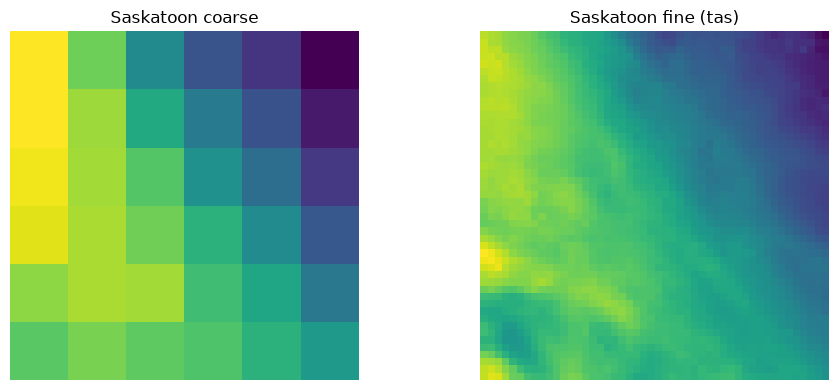

Vancouver fine shape: (48, 48) | Saskatoon fine shape: (48, 48) -> MATCH
Vancouver mean temp (K): 281.9 | Saskatoon: 277.27


In [14]:
import matplotlib.pyplot as plt
i = 0
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(coarse_stacks[i,0], origin="lower"); ax[0].set_title("Saskatoon coarse")
ax[1].imshow(fine_targets[i],    origin="lower"); ax[1].set_title(f"Saskatoon fine ({TEMP_VAR})")
for a in ax: a.axis("off")
plt.tight_layout(); plt.show()

# compare shape to Vancouver if that file is present
try:
    van = np.load("casr_vancouver_2015_2018.npz")
    print("Vancouver fine shape:", van["fine_targets"].shape[1:],
          "| Saskatoon fine shape:", fine_targets.shape[1:],
          "->", "MATCH" if van["fine_targets"].shape[1:] == fine_targets.shape[1:] else "MISMATCH (fix box/patch settings)")
    print("Vancouver mean temp (K):", round(float(van["fine_targets"].mean()),2),
          "| Saskatoon:", round(float(fine_targets.mean()),2))
except FileNotFoundError:
    print("(Vancouver .npz not found here — compare shapes manually when both are built)")